# Assignment 3 — Movie revenue and rating
**Student: z5429763**

This notebook records training-only exploration, leakage controls, feature construction, two algorithm families per task, a bounded hyperparameter search, and repeated training-only regression validation. The companion script trains the selected models and writes the required CSV files.

**Reproduction:** use Python 3.13 and `requirements.txt`. Put this notebook alongside `z5429763.py`. Supply the two input paths through the `ASSIGNMENT_DATA_ARGS` environment variable, parsed as two shell-style command-line arguments. For example, set it to the same two arguments supplied to the submission script, then execute this notebook with `jupyter nbconvert --execute`. Dataset paths are supplied by the caller.

The analysis runs more experiments than the submitted script; the two-minute budget applies to the script, not this model-development notebook.

The final revenue model is a 50/50 blend in log space of enriched-feature CatBoost and LightGBM. The classification model remains the depth-6 CatBoost model. All model selection and the regression improvement below use the training file only; the supplied test targets are not revisited for tuning.

In [1]:
import argparse
import os
import shlex
import time
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import ExtraTreesRegressor, ExtraTreesClassifier
from sklearn.metrics import root_mean_squared_log_error, f1_score, classification_report, ConfusionMatrixDisplay
import z5429763 as solution

parser = argparse.ArgumentParser()
parser.add_argument('train_file')
parser.add_argument('test_file')
data_args = parser.parse_args(shlex.split(os.environ['ASSIGNMENT_DATA_ARGS']))
train = pd.read_csv(data_args.train_file)
print('Python:', sys.version.split()[0], '| training shape:', train.shape)
print('Seed:', solution.SEED, '| model threads:', solution.THREADS)
assert train.imdb_id.is_unique
assert set(train.rating.unique()) == {'Low', 'Medium', 'High'}
assert (train.revenue >= 0).all()


Python: 3.13.17 | training shape: (16004, 27)
Seed: 42 | model threads: 4


## 1. Exploration and preparation
Only the supplied training data is opened at this stage. No combined train/test table, test-fitted encoder, test-target feature, or oversampling is used. The regression target is nonnegative revenue; the classification target is the three named labels. IMDb ID is retained only for output alignment.

In [2]:
display(train[list(solution.NUMERIC_COLUMNS) + ['revenue']].describe().round(2))
missing = train.isna().sum().rename('missing').to_frame()
missing['percent'] = 100 * missing['missing'] / len(train)
display(missing.loc[missing.missing > 0].sort_values('missing', ascending=False).round(2))
class_balance = train.rating.value_counts().rename_axis('rating').to_frame('count')
class_balance['percent'] = 100 * class_balance['count'] / len(train)
display(class_balance.round(2))
print('Duplicate IDs:', train.imdb_id.duplicated().sum())
print('Budget zero fraction:', round(train.budget.eq(0).mean(), 4))
print('Runtime zero fraction:', round(train.runtime.eq(0).mean(), 4))
print('Runtime > 300 minutes:', int(train.runtime.gt(300).sum()))
print('Status values:', sorted(train.status.unique()))
display(train.groupby('rating').vote_average.agg(['min', 'max', 'median']).round(3))


,budget,runtime,vote_count,imdb_votes,popularity,vote_average,revenue
count,1.600400e+04,16004.00,16004.00,16004.00,16004.00,16004.00,1.600400e+04
mean,1.255122e+07,103.49,973.60,48800.91,4.86,6.06,3.712825e+07
std,3.057422e+07,30.44,2608.90,145509.15,13.66,1.64,1.212716e+08
min,0.000000e+00,0.00,0.00,5.00,0.00,0.00,1.000000e+00
25%,0.000000e+00,91.00,23.00,950.75,1.19,5.60,3.314060e+05
50%,7.000000e+05,101.00,138.00,6155.00,2.56,6.30,3.205414e+06
75%,1.100000e+07,116.00,669.25,31584.50,5.31,7.00,2.052546e+07
max,7.000000e+08,999.00,41440.00,3250671.00,1024.51,10.00,2.927449e+09


,missing,percent
tagline,5376,33.59
music_composer,4563,28.51
director_of_photography,2817,17.60
keywords,2693,16.83
producers,1709,10.68
writers,750,4.69
production_companies,735,4.59
production_countries,378,2.36
spoken_languages,359,2.24
overview,155,0.97


,count,percent
rating,,
Medium,13356,83.45
Low,1902,11.88
High,746,4.66


Duplicate IDs: 0
Budget zero fraction: 0.4034
Runtime zero fraction: 0.0174
Runtime > 300 minutes: 12
Status values: ['Released']


,min,max,median
rating,,,
High,0.0,10.0,7.842
Low,0.0,10.0,4.880
Medium,0.0,10.0,6.400


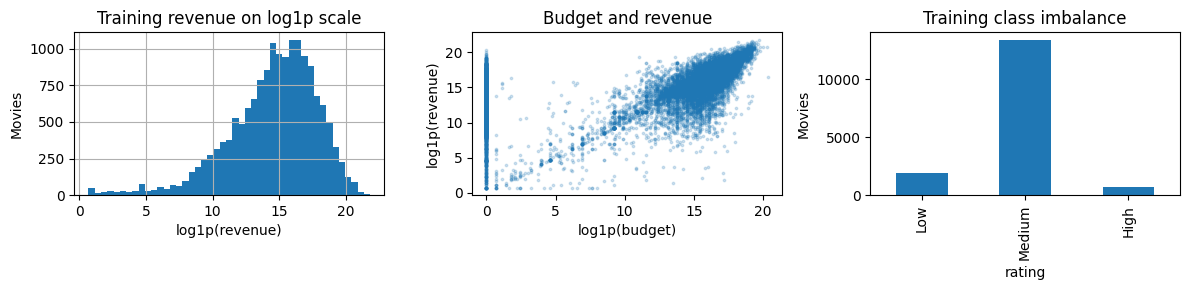

,revenue,budget,vote_count,imdb_votes,popularity
revenue,1.000,0.486,0.654,0.652,0.596
budget,0.486,1.000,0.504,0.529,0.463
vote_count,0.654,0.504,1.000,0.947,0.796
imdb_votes,0.652,0.529,0.947,1.000,0.764
popularity,0.596,0.463,0.796,0.764,1.000


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
np.log1p(train.revenue).hist(bins=45, ax=axes[0])
axes[0].set(title='Training revenue on log1p scale', xlabel='log1p(revenue)', ylabel='Movies')
axes[1].scatter(np.log1p(train.budget), np.log1p(train.revenue), s=3, alpha=.2)
axes[1].set(title='Budget and revenue', xlabel='log1p(budget)', ylabel='log1p(revenue)')
train.rating.value_counts().reindex(['Low', 'Medium', 'High']).plot.bar(ax=axes[2])
axes[2].set(title='Training class imbalance', ylabel='Movies')
plt.tight_layout()
plt.show()
plt.close(fig)
log_numeric = np.log1p(train[['revenue', 'budget', 'vote_count', 'imdb_votes', 'popularity']])
display(log_numeric.corr().round(3))


Revenue spans orders of magnitude, so regression learns `log1p(revenue)` and selects models using RMSLE, which matches the marking rule. Zero budget/runtime is treated as unknown with a missingness flag; negative/nonfinite numeric values become missing. Exceptional runtimes are retained because the data alone does not establish an error. CatBoost handles numeric NaNs without fitting an imputer. Missing categorical metadata gets an explicit sentinel.

The dominant Medium class makes accuracy alone misleading. I stratify the development split and select classifiers by Macro F1. Square-root inverse-frequency class weights are learned from each training partition only; no oversampling is used.

`rating` and `revenue` never appear in either task's predictors. The specification supplies `vote_average` as a numeric input and does not explicitly ban it. I use its observed value directly, without computing it from either target. Training data shows overlapping values across the three rating classes, so it is not an exact threshold encoding of the provided label. This empirical check does not establish data provenance; the assignment does not document how the two rating measurements were sourced. The training-only ablation below quantifies its contribution, and this remains a retrospective exercise in which the supplied input is assumed available at prediction time. Constant `status` and identifying `imdb_id` are excluded. Vote counts and popularity are supplied input measurements: this is a retrospective prediction exercise, not a claim that these variables are available before release.

## 2. Feature engineering and selection
The shared deterministic preprocessing function is in the companion script. Features include budget/votes/popularity and their log transforms, release year/month/quarter, missingness indicators, genres as fixed multi-hot flags, metadata list lengths and first entries (company, cast, country, language, writers, producers and keywords), director/composer categories, text lengths/word counts, and whether the localized title matches the original.

Dates use an explicit, fixed calendar rather than the current date. Text length features avoid downloading language models or learning vocabulary from the test set. CatBoost fits its categorical statistics solely on the fitting partition. The Extra Trees comparison uses training-fitted median imputation and one-hot encoding with rare-category grouping and safe handling of unseen categories. Neither preprocessing path fits anything on validation or test data. Fixed genre flags encode the documented domain, not selected test categories.

In [4]:
features = solution.preprocess(train)
cat_columns = solution.categorical_columns(features)
num_columns = features.columns.difference(cat_columns).tolist()
print('Feature count:', features.shape[1], '| categorical:', len(cat_columns))
display(features.head(3))
assert not set(solution.EXCLUDED_COLUMNS).intersection(features.columns)
fit_idx, valid_idx = train_test_split(
    np.arange(len(train)), test_size=.2, random_state=solution.SEED, stratify=train.rating
)
X_fit, X_valid = features.iloc[fit_idx], features.iloc[valid_idx]
y_reg_fit = np.log1p(train.revenue.iloc[fit_idx])
y_reg_valid = train.revenue.iloc[valid_idx]
y_cls_fit, y_cls_valid = train.rating.iloc[fit_idx], train.rating.iloc[valid_idx]
print('Fit/validation rows:', len(fit_idx), len(valid_idx))
display(pd.crosstab(train.rating, np.where(np.isin(np.arange(len(train)), fit_idx), 'fit', 'validation'), normalize='columns').round(4))


Feature count: 73 | categorical: 12


,budget,budget_missing,log1p_budget,runtime,runtime_missing,vote_count,vote_count_missing,log1p_vote_count,imdb_votes,imdb_votes_missing,...,original_title_length,original_title_words,original_title_missing,overview_length,overview_words,overview_missing,tagline_length,tagline_words,tagline_missing,title_is_original
0,35000000.0,0,17.370859,155.0,0,640.0,0,6.463029,44186.0,0,...,39.0,8.0,0,122.0,18.0,0,75.0,13.0,0,1
1,2000000.0,0,14.508658,94.0,0,0.0,0,0.000000,54.0,0,...,17.0,3.0,0,0.0,0.0,1,0.0,0.0,1,1
2,250000000.0,0,19.336971,115.0,0,893.0,0,6.795706,19194.0,0,...,5.0,1.0,0,204.0,34.0,0,33.0,7.0,0,1


Fit/validation rows: 12803 3201


col_0,fit,validation
rating,,
High,0.0466,0.0465
Low,0.1188,0.1190
Medium,0.8346,0.8344


## 3. Algorithm comparison and bounded hyperparameter tuning
Compare independent randomized trees (Extra Trees) with ordered categorical gradient boosting (CatBoost). A fixed stratified 80/20 split makes comparisons reproducible. Dummy predictions provide a lower reference. The small predeclared grid varies depth and boosting iterations, with regularization and a low learning rate; all choices are made on this training-only holdout. A single holdout is less robust than repeated cross-validation; scores are estimates and may vary on the tutors' unseen data. I keep the search bounded to respect runtime and avoid extensive holdout adaptation.

In [5]:
def tree_preprocessor():
    return ColumnTransformer([
        ('numeric', SimpleImputer(strategy='median', add_indicator=True), num_columns),
        ('category', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=20,
                                  sparse_output=True), cat_columns),
    ])
reg_results, cls_results = [], []
reg_models, cls_models = {}, {}
reg_results.append({'model': 'Dummy log mean', 'RMSLE': root_mean_squared_log_error(
    y_reg_valid, np.repeat(np.expm1(y_reg_fit.mean()), len(valid_idx))), 'fit_predict_seconds': 0.0})
cls_results.append({'model': 'Dummy majority', 'Macro F1': f1_score(
    y_cls_valid, np.repeat(y_cls_fit.mode().iloc[0], len(valid_idx)), average='macro'), 'fit_predict_seconds': 0.0})

t0 = time.perf_counter()
et_reg = make_pipeline(tree_preprocessor(), ExtraTreesRegressor(
    n_estimators=120, max_features=.8, min_samples_leaf=3, n_jobs=solution.THREADS, random_state=solution.SEED))
et_reg.fit(X_fit, y_reg_fit)
reg_results.append({'model': 'Extra Trees', 'RMSLE': root_mean_squared_log_error(
    y_reg_valid, solution.revenue_from_log(et_reg.predict(X_valid))), 'fit_predict_seconds': time.perf_counter()-t0})
reg_models['Extra Trees'] = et_reg

t0 = time.perf_counter()
et_cls = make_pipeline(tree_preprocessor(), ExtraTreesClassifier(
    n_estimators=120, max_features=.8, min_samples_leaf=2, class_weight='balanced',
    n_jobs=solution.THREADS, random_state=solution.SEED))
et_cls.fit(X_fit, y_cls_fit)
cls_results.append({'model': 'Extra Trees', 'Macro F1': f1_score(
    y_cls_valid, et_cls.predict(X_valid), average='macro'), 'fit_predict_seconds': time.perf_counter()-t0})
cls_models['Extra Trees'] = et_cls
print('Extra Trees comparison completed.')


Extra Trees comparison completed.


In [6]:
reg_grid = [dict(iterations=350, depth=6, learning_rate=.06, l2_leaf_reg=5),
            dict(iterations=650, depth=6, learning_rate=.06, l2_leaf_reg=5),
            dict(iterations=650, depth=7, learning_rate=.06, l2_leaf_reg=5)]
cls_grid = [dict(iterations=350, depth=5, learning_rate=.06, l2_leaf_reg=5),
            dict(iterations=650, depth=6, learning_rate=.06, l2_leaf_reg=5),
            dict(iterations=650, depth=7, learning_rate=.06, l2_leaf_reg=5)]
for config in reg_grid:
    name = f"CatBoost depth={config['depth']} iterations={config['iterations']}"
    t0 = time.perf_counter()
    model = solution.make_regressor(**config)
    model.fit(X_fit, y_reg_fit, cat_features=cat_columns)
    score = root_mean_squared_log_error(y_reg_valid, solution.revenue_from_log(model.predict(X_valid)))
    reg_results.append({'model': name, 'RMSLE': score, 'fit_predict_seconds': time.perf_counter()-t0, **config})
    reg_models[name] = model
for config in cls_grid:
    name = f"CatBoost depth={config['depth']} iterations={config['iterations']}"
    t0 = time.perf_counter()
    model = solution.make_classifier(**config)
    model.fit(X_fit, y_cls_fit, cat_features=cat_columns)
    score = f1_score(y_cls_valid, model.predict(X_valid).reshape(-1), average='macro')
    cls_results.append({'model': name, 'Macro F1': score, 'fit_predict_seconds': time.perf_counter()-t0, **config})
    cls_models[name] = model
reg_table = pd.DataFrame(reg_results).sort_values('RMSLE')
cls_table = pd.DataFrame(cls_results).sort_values('Macro F1', ascending=False)
display(reg_table.round(4))
display(cls_table.round(4))


,model,RMSLE,fit_predict_seconds,iterations,depth,learning_rate,l2_leaf_reg
3,CatBoost depth=6 iterations=650,1.8861,13.8074,650.0,6.0,0.06,5.0
4,CatBoost depth=7 iterations=650,1.8884,33.4242,650.0,7.0,0.06,5.0
2,CatBoost depth=6 iterations=350,1.9077,6.7701,350.0,6.0,0.06,5.0
1,Extra Trees,1.9249,70.3336,NaN,NaN,NaN,NaN
0,Dummy log mean,3.3223,0.0000,NaN,NaN,NaN,NaN


,model,Macro F1,fit_predict_seconds,iterations,depth,learning_rate,l2_leaf_reg
4,CatBoost depth=7 iterations=650,0.7558,44.5810,650.0,7.0,0.06,5.0
3,CatBoost depth=6 iterations=650,0.7526,32.0094,650.0,6.0,0.06,5.0
2,CatBoost depth=5 iterations=350,0.7282,14.4165,350.0,5.0,0.06,5.0
1,Extra Trees,0.7206,36.0885,NaN,NaN,NaN,NaN
0,Dummy majority,0.3032,0.0000,NaN,NaN,NaN,NaN


### Feature ablation and decision-weight check
To make feature selection evidence explicit, compare the selected categorical booster with a refit that excludes `vote_average` and its log/missing features. This ablation uses the same training-only split. A small predeclared 3×3 decision-weight grid tests whether increasing Low/High decision scores improves Macro F1; the default prediction is kept unless the holdout supports a change.

In [7]:
ablation_columns = [name for name in features.columns if 'vote_average' not in name]
ablation = solution.make_classifier()
ablation.fit(X_fit[ablation_columns], y_cls_fit, cat_features=cat_columns)
ablation_score = f1_score(y_cls_valid, ablation.predict(X_valid[ablation_columns]).reshape(-1), average='macro')
print('Classification Macro F1 without vote_average:', round(ablation_score, 4))
print('Best classification Macro F1 with vote_average:', round(cls_table.iloc[0]['Macro F1'], 4))
weight_model = cls_models['CatBoost depth=6 iterations=650']
probabilities = weight_model.predict_proba(X_valid)
weight_results = []
for low_weight in [1, 1.5, 2]:
    for high_weight in [1, 1.5, 2]:
        weights = {'Low': low_weight, 'Medium': 1, 'High': high_weight}
        adjusted = weight_model.classes_[np.argmax(probabilities * [weights[label] for label in weight_model.classes_], axis=1)]
        weight_results.append({'Low weight': low_weight, 'High weight': high_weight,
                               'Macro F1': f1_score(y_cls_valid, adjusted, average='macro')})
weight_table = pd.DataFrame(weight_results).sort_values('Macro F1', ascending=False, kind='stable')
display(weight_table.round(4))
# The final script uses direct class predictions; verify that the grid supports it.
assert weight_table.iloc[0]['Low weight'] == 1 and weight_table.iloc[0]['High weight'] == 1


Classification Macro F1 without vote_average: 0.6536
Best classification Macro F1 with vote_average: 0.7558


,Low weight,High weight,Macro F1
0,1.0,1.0,0.7526
1,1.0,1.5,0.7437
3,1.5,1.0,0.7386
6,2.0,1.0,0.7315
4,1.5,1.5,0.7297
2,1.0,2.0,0.7288
7,2.0,1.5,0.7231
5,1.5,2.0,0.7149
8,2.0,2.0,0.7080


## 4. CatBoost reference model and classification choice
The tables report observed scores, not assumed performance. The selected depth-6, 650-iteration CatBoost configuration is checked to remain within 0.01 of the validation optimum in each task. I prefer the shallower booster over depth 7 for its lower categorical/multiclass training cost and reduced capacity; the 350-iteration alternative checks whether stopping substantially earlier loses validation performance. Small score differences on a single holdout are not strong evidence for doubling training cost. The tables expose any tradeoff rather than calling the chosen model the numerical optimum when it is not. Depth/iteration changes test model capacity; residual and class diagnostics below expose remaining errors. The final script retains this classification model; the reference revenue model is superseded by the enriched ensemble evaluated below. Both final components use all training rows when generating outputs. No test results influence model choice.

Model-based PredictionValuesChange importance is computed from the fitted training model; it indicates relative use, not causal effect. Correlated raw/log features can share importance and high-cardinality metadata can be influential. I retain the compact engineered feature set rather than repeatedly selecting subsets on one validation split.

The matched depth-6/650 ablation gives **0.7526 Macro F1 with `vote_average` versus 0.6536 without it**, a 0.0990 difference. The 0.7558 value printed above is the separate depth-7 grid maximum. Of 2,081 distinct training `vote_average` values, 156 occur in more than one rating class; overlap rules out an exact threshold mapping of this field to the target but does not document the fields' provenance. No target-derived encoding is constructed.


RMSLE gap to validation optimum: 0.0
Macro F1 gap to validation optimum: 0.0032
Selected regression: CatBoost depth=6 iterations=650
Selected classification: CatBoost depth=6 iterations=650


,feature,regression_importance
0,log1p_budget,13.570
1,budget,10.988
2,vote_count,6.680
3,release_year,5.822
4,log1p_imdb_votes,5.517
5,imdb_votes,5.157
6,original_language,4.643
7,log1p_vote_count,4.569
8,runtime,4.320
9,production_companies_first,3.974


,feature,classification_importance
0,log1p_vote_average,17.006
1,vote_average,16.572
2,release_year,5.438
3,imdb_votes,4.944
4,log1p_imdb_votes,4.471
5,genres_first,3.963
6,runtime,3.901
7,original_language,3.216
8,production_countries_first,3.159
9,log1p_vote_count,2.513


              precision    recall  f1-score   support

         Low       0.59      0.77      0.67       381
      Medium       0.95      0.90      0.92      2671
        High       0.58      0.79      0.66       149

    accuracy                           0.88      3201
   macro avg       0.71      0.82      0.75      3201
weighted avg       0.89      0.88      0.88      3201



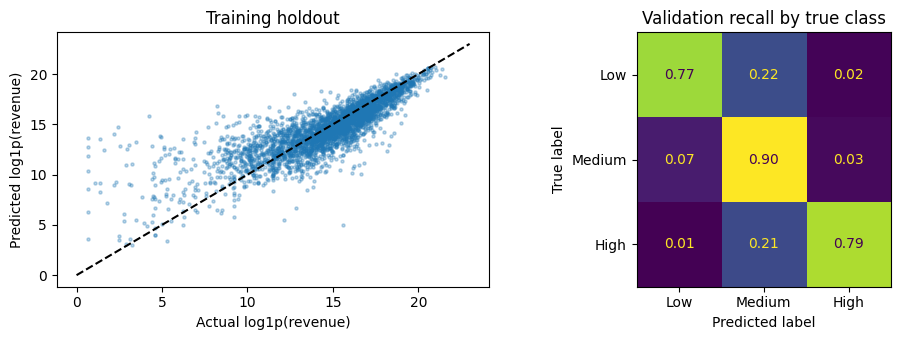

,imdb_id,actual,predicted,absolute_log_error
743,tt15742904,1.0,827767.128,12.933
1614,tt13491110,10.0,2478286.086,12.325
1025,tt3805180,3.0,787007.901,12.190
1033,tt19864988,1.0,327147.446,12.005
144,tt3850358,8.0,1273919.552,11.860


,samples,correct,recall,error_rate
actual,,,,
High,149,117,0.7852,0.2148
Low,381,292,0.7664,0.2336
Medium,2671,2392,0.8955,0.1045


,samples,RMSLE
budget_known,,
False,1292,2.3447
True,1909,1.4980


Validation RMSLE conditional bootstrap 95% interval: [1.7827 1.9899]
Validation Macro F1 conditional bootstrap 95% interval: [0.7277 0.7718]


The strongest regression importance signals are **log1p_budget, budget, vote_count**; classification emphasizes **log1p_vote_average, vote_average, release_year**. These are predictive associations rather than causal effects. The weakest-recall class is **Low** (76.6% recall across 381 validation examples). The class-normalized confusion matrix and per-class error rates prevent the dominant Medium population from masking minority-class errors. The bootstrap intervals condition on this split and trained models; they exclude uncertainty from retraining, dataset shift, or further model selection.

In [8]:
best_reg_name = 'CatBoost depth=6 iterations=650'
best_cls_name = 'CatBoost depth=6 iterations=650'
selected_reg_score = float(reg_table.loc[reg_table.model.eq(best_reg_name), 'RMSLE'].iloc[0])
selected_cls_score = float(cls_table.loc[cls_table.model.eq(best_cls_name), 'Macro F1'].iloc[0])
print('RMSLE gap to validation optimum:', round(selected_reg_score-reg_table.RMSLE.min(), 4))
print('Macro F1 gap to validation optimum:', round(cls_table['Macro F1'].max()-selected_cls_score, 4))
assert selected_reg_score <= reg_table.RMSLE.min() + .01
assert selected_cls_score >= cls_table['Macro F1'].max() - .01
print('Selected regression:', best_reg_name)
print('Selected classification:', best_cls_name)
best_reg = reg_models[best_reg_name]
best_cls = cls_models[best_cls_name]
assert best_reg_name.startswith('CatBoost') and best_cls_name.startswith('CatBoost')
for model, expected in [(best_reg, solution.REGRESSION_PARAMS), (best_cls, solution.CLASSIFICATION_PARAMS)]:
    for key, value in expected.items():
        assert model.get_params()[key] == value, (key, model.get_params()[key], value)
reg_importance = pd.Series(best_reg.feature_importances_, index=features.columns).sort_values(ascending=False)
cls_importance = pd.Series(best_cls.feature_importances_, index=features.columns).sort_values(ascending=False)
display(pd.DataFrame({'feature': reg_importance.head(12).index, 'regression_importance': reg_importance.head(12).values}).round(3))
display(pd.DataFrame({'feature': cls_importance.head(12).index, 'classification_importance': cls_importance.head(12).values}).round(3))
valid_reg = solution.revenue_from_log(best_reg.predict(X_valid))
valid_cls = best_cls.predict(X_valid).reshape(-1)
print(classification_report(y_cls_valid, valid_cls, labels=['Low', 'Medium', 'High'], zero_division=0))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].scatter(np.log1p(y_reg_valid), np.log1p(valid_reg), s=5, alpha=.3)
axes[0].plot([0, 23], [0, 23], '--', color='black')
axes[0].set(xlabel='Actual log1p(revenue)', ylabel='Predicted log1p(revenue)', title='Training holdout')
ConfusionMatrixDisplay.from_predictions(y_cls_valid, valid_cls, labels=['Low', 'Medium', 'High'], normalize='true', values_format='.2f', ax=axes[1], colorbar=False)
axes[1].set_title('Validation recall by true class')
plt.tight_layout(); plt.show(); plt.close(fig)
worst = pd.DataFrame({'imdb_id': train.imdb_id.iloc[valid_idx].to_numpy(), 'actual': y_reg_valid.to_numpy(), 'predicted': valid_reg})
worst['absolute_log_error'] = np.abs(np.log1p(worst.actual) - np.log1p(worst.predicted))
display(worst.nlargest(5, 'absolute_log_error').round(3))
# Compare error rates with their denominators, rather than raw error counts.
by_class = pd.DataFrame({'actual': y_cls_valid.to_numpy(), 'correct': valid_cls == y_cls_valid.to_numpy()})
class_evidence = by_class.groupby('actual').agg(samples=('correct', 'size'), correct=('correct', 'sum'), recall=('correct', 'mean'))
class_evidence['error_rate'] = 1 - class_evidence['recall']
display(class_evidence.round(4))
revenue_evidence = pd.DataFrame({'budget_known': train.budget.iloc[valid_idx].to_numpy() > 0,
                               'squared_log_error': (np.log1p(y_reg_valid.to_numpy()) - np.log1p(valid_reg))**2})
budget_errors = revenue_evidence.groupby('budget_known').agg(samples=('squared_log_error', 'size'), MSE_log=('squared_log_error', 'mean'))
budget_errors['RMSLE'] = np.sqrt(budget_errors.pop('MSE_log'))
display(budget_errors.round(4))
# Conditional bootstrap interval: no refitting and no test-set involvement.
rng = np.random.default_rng(solution.SEED)
reg_boot, cls_boot = [], []
for _ in range(200):
    indices = rng.integers(0, len(valid_idx), len(valid_idx))
    reg_boot.append(root_mean_squared_log_error(y_reg_valid.to_numpy()[indices], valid_reg[indices]))
    cls_boot.append(f1_score(y_cls_valid.to_numpy()[indices], valid_cls[indices], average='macro'))
print('Validation RMSLE conditional bootstrap 95% interval:', np.quantile(reg_boot, [.025, .975]).round(4))
print('Validation Macro F1 conditional bootstrap 95% interval:', np.quantile(cls_boot, [.025, .975]).round(4))
weakest = class_evidence.recall.idxmin()
reg_top = ', '.join(reg_importance.head(3).index)
cls_top = ', '.join(cls_importance.head(3).index)
display(Markdown(f"The strongest regression importance signals are **{reg_top}**; classification emphasizes **{cls_top}**. These are predictive associations rather than causal effects. The weakest-recall class is **{weakest}** ({class_evidence.loc[weakest, 'recall']:.1%} recall across {int(class_evidence.loc[weakest, 'samples'])} validation examples). The class-normalized confusion matrix and per-class error rates prevent the dominant Medium population from masking minority-class errors. The bootstrap intervals condition on this split and trained models; they exclude uncertainty from retraining, dataset shift, or further model selection."))


## Interpretation of the observed validation errors

**Budget availability is the main observed regression weakness:** 1,292 of 3,201 validation movies (40.4%) have an unknown/zero budget. Their RMSLE is 2.3447, compared with 1.4980 among the 1,909 known-budget movies (59.6%). Keeping a budget-missing flag lets the model recognize this difference, but does not recover the missing financial signal. The largest log errors involve recorded revenues of only 1–10 predicted in the millions. These could reflect reporting issues or unusual films; the dataset does not establish which, so I retain them rather than invent corrected labels. Future work should test improvements on training-only splits, especially for missing budgets and very small revenues.

**Minority-class precision remains weak despite good recall:** Low has the weakest recall (0.7664 on 381 examples), while High recall is 0.7852 on only 149 examples. High/Low precision is around 0.58/0.59, versus 0.95 for Medium. Increasing minority decision weights worsened Macro F1 in the grid, so the final classifier keeps its original decision rule. The depth-7 classifier improves Macro F1 by only 0.0032 while taking 46.05 rather than 37.77 seconds on this split; the depth-6 classifier is selected to preserve runtime margin.



## 5. Improving the regression model using only training data

The fixed seed-42 split is retained for an honest before/after comparison. A second split (seed 2026) checks whether the chosen improvement repeats; it is not chosen because of its score. Baseline and candidate use identical fitting/validation rows within each split. All 3,201 validation observations are included, including tiny reported revenues.

The final regressor adds secondary cast/crew, company/country/language entries, normalized complete lists, decade, log ratios between votes/popularity and budget/runtime, and small-value flags. These are row-wise input transformations with no target-derived features. LightGBM category vocabularies are fitted only on the fitting partition; unknown validation/prediction values become missing. CatBoost uses its own training-only categorical statistics.

Final CatBoost parameters: 1,200 iterations, depth 7, learning rate 0.04, L2=10, max CTR complexity=1. Final LightGBM parameters: 276 estimators, 63 leaves, learning rate 0.025, minimum child samples=20, L2=20, feature fraction=0.9. The tree count 276 came from early stopping on the primary training holdout; it is fixed for the second split and final fit. Limiting categorical interactions keeps CPU training practical.

Both components learn log1p(revenue). Their log predictions receive equal weight before expm1 conversion, matching the RMSLE objective. This reduces differing model errors rather than averaging raw dollars. Classification features and parameters are preserved.

Exploratory results on the primary split (all training-only):

| Approach | RMSLE |
|---|---:|
| Original CatBoost | 1.8861 |
| Enriched CatBoost, 900/depth6/CTR4 | 1.8896 |
| Enriched CatBoost, 1200/depth7/CTR1 | 1.8834 |
| Enriched native-category LightGBM, 31/63 leaves | 1.9248 / 1.9092 |
| Sparse entity/text Ridge, alpha 10/100 | 2.0486 / 1.9807 |
| Sparse entity/text LightGBM, 15/31 leaves | 1.9434 / 1.9303 |
| Sparse entity/text XGBoost, depth5/800 trees | 1.9430 (137 seconds for regression alone) |
| Separate known/unknown-budget regressors | 1.8974 |
| Low-revenue mixture, threshold 1000/10000 | 1.8965 / 1.8728 |
| Selected equal-weight CatBoost + LightGBM | 1.8640 |

Adding a low-revenue mixture to the selected ensemble achieved 1.8561 on this split, but its incremental paired bootstrap interval was [-0.0021, 0.0177], including no improvement. It requires three further regression/gating models. I retain the simpler two-component blend; no approach reached 1.7. Multiple comparisons make the primary result optimistic, so the repeated split is reported and no hidden-test guarantee is made. Full experiment limitations are recorded in REGRESSION_EXPERIMENTS.md.

In [9]:
# Reproduce final before/after comparisons using only data_args.train_file.
import json
from time import perf_counter
def compare(train, seed):
    fitting, validation = train_test_split(
        np.arange(len(train)), test_size=0.2, random_state=seed, stratify=train.rating
    )
    target = np.log1p(train.revenue.to_numpy())
    features = solution.preprocess(train)
    started = perf_counter()
    baseline = solution.make_regressor()
    baseline.fit(
        features.iloc[fitting],
        target[fitting],
        cat_features=solution.categorical_columns(features),
    )
    baseline_prediction = np.maximum(0, baseline.predict(features.iloc[validation]))
    baseline_seconds = perf_counter() - started
    started = perf_counter()
    candidate = solution.RevenueRegressor().fit(train.iloc[fitting], target[fitting])
    prediction = np.maximum(0, candidate.predict(train.iloc[validation]))
    candidate_seconds = perf_counter() - started
    error = (target[validation] - prediction) ** 2
    baseline_error = (target[validation] - baseline_prediction) ** 2
    rng = np.random.default_rng(42)
    bootstrap, improvement = [], []
    for _ in range(1000):
        sample = rng.integers(0, len(validation), len(validation))
        score = float(np.sqrt(error[sample].mean()))
        bootstrap.append(score)
        improvement.append(float(np.sqrt(baseline_error[sample].mean())) - score)
    subgroups = {}
    for name, mask in {
        "budget_unknown": train.budget.iloc[validation].eq(0).to_numpy(),
        "budget_known": train.budget.iloc[validation].gt(0).to_numpy(),
        "revenue_le_1000": train.revenue.iloc[validation].le(1000).to_numpy(),
        "revenue_gt_1000": train.revenue.iloc[validation].gt(1000).to_numpy(),
    }.items():
        subgroups[name] = dict(
            rows=int(mask.sum()),
            RMSLE=float(np.sqrt(error[mask].mean())),
            squared_log_error_share=float(error[mask].sum() / error.sum()),
        )
    return dict(
        seed=seed,
        fitting_rows=len(fitting),
        validation_rows=len(validation),
        baseline_RMSLE=float(np.sqrt(baseline_error.mean())),
        candidate_RMSLE=float(np.sqrt(error.mean())),
        baseline_seconds=baseline_seconds,
        candidate_seconds=candidate_seconds,
        candidate_RMSLE_95_CI=np.quantile(bootstrap, [0.025, 0.975]).tolist(),
        improvement_95_CI=np.quantile(improvement, [0.025, 0.975]).tolist(),
        subgroups=subgroups,
        cat_feature_importance=sorted(
            [
                dict(feature=name, importance=float(value))
                for name, value in zip(
                    candidate.cat_model.feature_names_,
                    candidate.cat_model.feature_importances_,
                )
            ],
            key=lambda row: row["importance"],
            reverse=True,
        )[:12],
        lightgbm_feature_gain=sorted(
            [
                dict(feature=name, gain=float(value))
                for name, value in zip(
                    candidate.feature_names,
                    candidate.lgb_model.booster_.feature_importance(
                        importance_type="gain"
                    ),
                )
            ],
            key=lambda row: row["gain"],
            reverse=True,
        )[:12],
    )
regression_results = []
for validation_seed in [42, 2026]:
    result = compare(train, validation_seed)
    regression_results.append(result)
    print('Completed seed', validation_seed, 'baseline RMSLE:', round(result['baseline_RMSLE'], 6),
          'ensemble RMSLE:', round(result['candidate_RMSLE'], 6))
display(pd.DataFrame([{key: row[key] for key in ['seed', 'fitting_rows', 'validation_rows', 'baseline_RMSLE', 'candidate_RMSLE', 'baseline_seconds', 'candidate_seconds']} for row in regression_results]).round(4))
Path('experiments').mkdir(exist_ok=True)
Path('experiments/regression_results.json').write_text(json.dumps(regression_results, indent=2))


Completed seed 42 baseline RMSLE: 1.886051 ensemble RMSLE: 1.864038


Completed seed 2026 baseline RMSLE: 1.784353 ensemble RMSLE: 1.760112


,seed,fitting_rows,validation_rows,baseline_RMSLE,candidate_RMSLE,baseline_seconds,candidate_seconds
0,42,12803,3201,1.8861,1.8640,13.0139,21.1752
1,2026,12803,3201,1.7844,1.7601,13.8410,26.3731


6607

In [10]:
for row in regression_results:
    print('Split seed:', row['seed'])
    print('Candidate conditional bootstrap 95% RMSLE interval:', np.round(row['candidate_RMSLE_95_CI'], 4))
    print('Paired bootstrap 95% improvement interval:', np.round(row['improvement_95_CI'], 4))
    display(pd.DataFrame(row['subgroups']).T.round(4))
print('Final ensemble CatBoost component importance (primary split):')
display(pd.DataFrame(regression_results[0]['cat_feature_importance']).round(3))
print('Final ensemble LightGBM component gain (primary split; different scale):')
display(pd.DataFrame(regression_results[0]['lightgbm_feature_gain']).round(3))
assert regression_results[0]['candidate_RMSLE'] < regression_results[0]['baseline_RMSLE']
assert regression_results[1]['candidate_RMSLE'] < regression_results[1]['baseline_RMSLE']
print('Improvement repeated on both splits. Target RMSLE <= 1.7 reached:',
      all(row['candidate_RMSLE'] <= 1.7 for row in regression_results))


Split seed: 42
Candidate conditional bootstrap 95% RMSLE interval: [1.764  1.9639]
Paired bootstrap 95% improvement interval: [0.005  0.0397]


,rows,RMSLE,squared_log_error_share
budget_unknown,1292.0,2.3239,0.6274
budget_known,1909.0,1.4735,0.3726
revenue_le_1000,112.0,5.7267,0.3302
revenue_gt_1000,3089.0,1.5529,0.6698


Split seed: 2026
Candidate conditional bootstrap 95% RMSLE interval: [1.6755 1.8439]
Paired bootstrap 95% improvement interval: [0.006  0.0416]


,rows,RMSLE,squared_log_error_share
budget_unknown,1284.0,2.1222,0.5831
budget_known,1917.0,1.4685,0.4169
revenue_le_1000,85.0,5.0938,0.2224
revenue_gt_1000,3116.0,1.5731,0.7776


Final ensemble CatBoost component importance (primary split):


,feature,importance
0,budget_small,6.802
1,log1p_budget,5.655
2,original_language,4.884
3,budget,4.847
4,log1p_imdb_votes,4.555
5,production_companies_first,4.284
6,runtime,4.237
7,release_year,4.219
8,budget_per_runtime,4.031
9,vote_count,3.835


Final ensemble LightGBM component gain (primary split; different scale):


,feature,gain
0,budget,1039883.488
1,vote_count,275130.748
2,imdb_votes,146377.892
3,log1p_budget,108846.310
4,production_countries_all,73515.548
5,release_year,71949.008
6,budget_per_runtime,64025.068
7,genres_all,58530.785
8,runtime,53837.632
9,popularity,47594.134


Improvement repeated on both splits. Target RMSLE <= 1.7 reached: False


## 6. Interpretation, limitations and delivery

Regression improves on both fixed training-only splits: 1.8861→1.8640 and 1.7844→1.7601, but remains above the 1.7 full-mark threshold. The primary paired interval supports a small improvement; these conditional intervals do not account for the entire model search or distribution shift.

The difficulty is concentrated, not uniform: only 112 of 3,201 primary validation observations (3.5%) have reported revenue ≤1000, yet they contribute about 33% of the baseline squared log error. The selected ensemble still has RMSLE about 5.73 on this subgroup and 1.55 on the remaining observations. These subgroup scores are diagnostics; the overall score retains every row. Unknown-budget films remain substantially harder (about 2.32 versus 1.47 for known budgets). Metadata lacks a documented reporting scope/currency reconciliation and cannot establish whether the tiny values represent actual takings, partial reporting or unit differences; no labels are corrected without evidence.

More capacity was insufficient: the enriched depth-7 CatBoost reaches training log RMSE about 1.62 but validation RMSLE about 1.88. Sparse text/entity models and explicitly modeling low revenues did not close the gap. The low-revenue gate has good ranking (AUROC about 0.94 at threshold 1000) but its conditional-mean mixture still scores about 1.90 overall; identifying a risk of tiny revenue is not the same as predicting its log value accurately.

Reducing RMSLE from 1.8640 to 1.7 requires roughly a further 16.8% reduction in squared log error. The experiments establish a remaining empirical gap, not a proof that no legal model could ever reach 1.7. Repeated holdout variation is larger than the achieved improvement; further work would require more reliable financial predictors or demonstrably stronger training-only validation, within the runtime budget.

The official script remains self-contained and accepts exactly two caller-supplied input paths. It trains the final revenue ensemble and unchanged classifier, then writes the two required two-column CSVs. Revised CSV generation does not read test targets as features and does not revisit their metrics for tuning. No train/test concatenation, test-fitted encoder, external data, target-derived input or hard-coded prediction is used.

Submit z5429763.py and this executed notebook (<3 MB). Confirm total runtime on CSE Python 3.13. All notebook outputs are embedded; the assignment does not require separate screenshots. Hidden-test scores and CSE time remain unverified.

## 7. Robust loss, sample weighting and budget sensitivity

All interventions below use only the fitting partition of the original seed-42 training split; all 3,201 validation rows retain equal scoring weight. This tests modeling choices, not whether labels are proven wrong.

| Fitting intervention | Overall validation RMSLE | Revenue >1000 subgroup |
|---|---:|---:|
| Current ensemble | **1.864038** | 1.552917 |
| Remove fitting rows with revenue ≤1000 | 1.994369 | **1.489741** |
| Weight those fitting rows by 0.25 / 0.5 | 1.887414 / 1.872856 | 1.508418 / 1.526086 |
| CatBoost Huber δ=1 / δ=2, LightGBM Huber α=0.9 | 1.962086 / 1.952424 | 1.551785 / 1.547341 |
| Predict missing budgets, preserving original missing flag | 1.868230 | 1.563303 |
| Downweight top 5% of fitting-only OOF residuals to 0.25 | 1.874666 | 1.535206 |

Removing/downweighting improves the majority but worsens rare-case errors sufficiently to increase overall RMSLE. OOF flags come from a 3-fold model inside the fitting partition; validation labels never select the 641 flagged fitting rows. A large OOF residual is not proof of an erroneous label. These tests reject these configurations on one split, not all possible robust methods.

Budget missingness and extreme revenues interact: 57 unknown-budget validation films with revenue ≤1000 account for 27.7% of total squared log error. Nevertheless, after excluding tiny revenues for subgroup diagnosis only, unknown-budget films still score 1.777 versus 1.384 for known budgets. No such records are removed from the official overall score.

Holding the same 1,909 known-budget validation films, trained model, and other inputs fixed, masking budget changes RMSLE from 1.473480 to 2.143281. This is sensitivity to information used by this model; it does not reproduce the real missing-data mechanism or establish a population causal effect. Predictive budget imputation did not improve the tested overall result.

A plateau from more trees does not by itself diagnose a parameter error. Loss alignment, representation, missingness, label provenance, capacity and variance are competing explanations. The current log-squared objective matches RMSLE; Huber and reweighting change that objective. The current model is retained based on the complete validation score.

These are observed supplementary experiments, with results and reproduction code in ROBUSTNESS_DIAGNOSTICS.md and experiments/robustness_validation.py. No assignment test targets are used for these decisions. No production model or prediction CSV changes are made from this experiment.


## 8. Review and ablation of additional proposed changes

Training-only ablations tested missing-value sentinels and interactions, fit-only entity frequencies, release/metadata proxies, stronger LightGBM regularization, CTR complexity, and 0.5/0.65 CatBoost blend weights. All validation rows remain included. Frequency dictionaries are learned from the fitting partition only; no validation/test frequencies or targets enter fitting.

| Scheme (CatBoost weight) | seed 42 RMSLE | seed 2026 RMSLE |
|---|---:|---:|
| Retained production ensemble (0.5) | **1.864038** | **1.760112** |
| Entity frequencies only (0.65) | 1.858857 | 1.763365 |
| All feature changes, original model parameters (0.65) | 1.859335 | 1.763704 |
| Revised features + regularized LightGBM, CTR=1 (0.5) | **1.856592** | 1.767086 |
| Pasted executable combination, CTR=2 (0.65) | 1.863021 | 1.773132 |
| Pasted combination with CTR=1 fallback (0.65) | 1.859139 | 1.767270 |

The literal-code comparison includes missing-category counts, the duplicate vote_diff feature, its original runtime-NaN handling, and the executable block's default min_data_per_group. The revised version excludes missing sentinels from entity counts, handles missing runtime explicitly, removes the duplicate, and tests the prose's min_data_per_group=50. Neither interpretation improved both splits.

Native numerical NaNs are supported by both estimators, and the original pipeline has missing flags; an unavailable budget/runtime ratio is not automatically an implementation bug. Frequency can proxy dataset prevalence, not verified company scale. Translated titles and multiple countries/languages do not prove distribution arrangements. The provided schema has no homepage column, which is not invented.

CTR=1 does not prevent trees from learning feature interactions. The tested CTR=2 component took substantially longer: 57.60 vs 21.68 seconds on the primary fit, and 66.16 vs 35.30 on the second fit, with their other parameter differences recorded. These are regression-component times, not full submission timing. The claimed fixed gain and guaranteed notebook marks are not supported by these observations.

The best primary-split gain did not repeat on the second split. Both are previously used development partitions; no fresh-score guarantee is claimed. No candidate met the precondition of improving both, so further split selection was not used to search for a favorable score. The production code and prediction CSVs remain unchanged. Full configurations, scores, limitations and reproduction instructions are in PROPOSAL_REVIEW.md and experiments/proposal_validation.py.
